### Importando as Bibliotecas

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', None)

def drop_reset_index(df):
    df = df.dropna()
    df = df.reset_index(drop=True)
    df.index += 1
    return df

def plot_profit_acu(dataframe, title_text):
    dataframe['Profit_acu'] = dataframe.Profit.cumsum()
    n_apostas = dataframe.shape[0]
    profit = round(dataframe.Profit_acu.tail(1).item(), 2)
    ROI = round((dataframe.Profit_acu.tail(1) / n_apostas * 100).item(), 2)
    drawdown = dataframe['Profit_acu'] - dataframe['Profit_acu'].cummax()
    drawdown_maximo = round(drawdown.min(), 2)
    winrate_medio = round((dataframe['Profit'] > 0).mean() * 100, 2)
    desvio_padrao = round(dataframe['Profit'].std(), 2)
    dataframe.Profit_acu.plot(title=title_text, xlabel='Entradas', ylabel='Stakes')
    print("Metodo:",title_text)
    print("Profit:", profit, "stakes em", n_apostas, "jogos")
    print("ROI:", ROI, "%")
    print("Drawdown Maximo Acumulado:", drawdown_maximo)
    print("Winrate Medio:", winrate_medio, "%")
    print("Desvio Padrao:", desvio_padrao)
    print("")

### Importando a Base de Dados

In [ ]:
df = pd.read_csv("https://github.com/futpythontrader/YouTube/raw/main/Luke/Bases_de_Dados/Base_de_Dados_FutPythonPunter.csv")
flt = ((df.Odd_H != 0) & (df.Odd_D != 0) & (df.Odd_A != 0) & (df.Odd_LayHome != 0) & (df.Odd_LayDraw != 0) & (df.Odd_LayAway != 0) &
       (df.Odd_Over25 != 0) & (df.Odd_Under25 != 0) & (df.Odd_BTTS_Yes != 0) & (df.Odd_BTTS_No != 0))
df = df[flt]

df = df[['Date','League','Season','Home','Away','Goals_H_FT','Goals_A_FT',
            'Odd_H','Odd_D','Odd_A','Odd_LayHome','Odd_LayDraw','Odd_LayAway',
            'Odd_Over25','Odd_Under25','Odd_BTTS_Yes','Odd_BTTS_No',
            'Goals_Minutes_Home','Goals_Minutes_Away']]
df.columns = ['Date','League','Season','Home','Away','Goals_H','Goals_A',
              'Odd_H','Odd_D','Odd_A','Odd_LH','Odd_LD','Odd_LA',
              'Odd_Over25','Odd_Under25','Odd_BTTS_Yes','Odd_BTTS_No',
              'Min_H','Min_A']
df = drop_reset_index(df)

In [ ]:
df['Back_Home'] = np.where((df['Goals_H'] >  df['Goals_A']), 1, 0)
df['Profit_Back_Home'] = np.where((df['Back_Home'] == 1), df['Odd_H']-1, -1)

df['Back_Draw'] = np.where((df['Goals_H'] == df['Goals_A']), 1, 0)
df['Profit_Back_Draw'] = np.where((df['Back_Draw'] == 1), df['Odd_D']-1, -1)

df['Back_Away'] = np.where((df['Goals_H']  < df['Goals_A']), 1, 0)
df['Profit_Back_Away'] = np.where((df['Back_Away'] == 1), df['Odd_A']-1, -1)

df['Lay_Home'] = np.where((df['Goals_H'] <= df['Goals_A']), 1, 0)
df['Profit_Lay_Home'] = np.where((df['Lay_Home'] == 1), df['Odd_LH']-1, -1)

df['Lay_Draw'] = np.where((df['Goals_H'] != df['Goals_A']), 1, 0)
df['Profit_Lay_Draw'] = np.where((df['Lay_Draw'] == 1), df['Odd_LD']-1, -1)

df['Lay_Away'] = np.where((df['Goals_H'] >= df['Goals_A']), 1, 0)
df['Profit_Lay_Away'] = np.where((df['Lay_Away'] == 1), df['Odd_LA']-1, -1)

df['Over25'] = np.where((df['Goals_H'] + df['Goals_A']) > 2, 1, 0)
df['Profit_Over25'] = np.where((df['Over25'] == 1), df['Odd_Over25']-1, -1)

df['Under25'] = np.where((df['Goals_H'] + df['Goals_A']) < 3, 1, 0)
df['Profit_Under25'] = np.where((df['Under25'] == 1), df['Odd_Under25']-1, -1)

df['BTTS'] = np.where((df['Goals_H'] > 0) & (df['Goals_A'] > 1), 1, 0)
df['Profit_BTTS'] = np.where((df['BTTS'] == 1), df['Odd_BTTS_Yes']-1, -1)

df['Lay_0x1'] = np.where((df['Goals_H'] == 0) & (df['Goals_A'] == 1), 0, 1)
df['Lay_1x0'] = np.where((df['Goals_H'] == 1) & (df['Goals_A'] == 0), 0, 1)

df['Lay_Gol_H'] = np.where((df['Goals_H'] > df['Goals_A']) & (df['Goals_H'] >= 4), 0, 1)
df['Lay_Gol_A'] = np.where((df['Goals_A'] > df['Goals_H']) & (df['Goals_A'] >= 4), 0, 1)

Metodo: Back_Home
Profit: -7939.27 stakes em 105738 jogos
ROI: -7.51 %
Drawdown Maximo Acumulado: -7943.82
Winrate Medio: 43.48 %
Desvio Padrao: 1.2



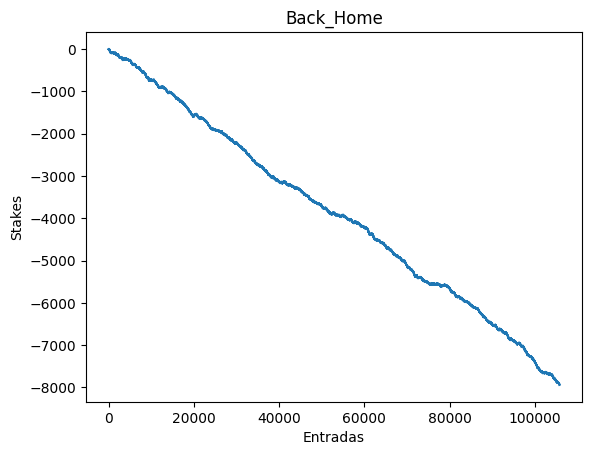

In [ ]:
df['Profit'] = df['Profit_Back_Home']
plot_profit_acu(df, 'Back_Home')